# Random Forest y MLP base · Dayron Quiñónez
Este notebook corresponde a la segunda tarea de Dayron: **Random Forest con búsqueda de hiperparámetros y MLP por defecto**. Reutiliza el pipeline de Luis y la evaluación común. La implementación está en `src/ic_g7/experimentos_dayron.py` para poder ejecutar lo mismo desde una terminal.

Se usa únicamente entrenamiento. No se elige, exporta ni conecta el modelo final a Streamlit en esta etapa.

In [1]:
from pathlib import Path
import json
import sys

# Permite abrir el notebook desde la raíz del repo o desde notebooks/.
raiz = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "ic_g7").is_dir())
if str(raiz / "src") not in sys.path:
    sys.path.insert(0, str(raiz / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from ic_g7 import config
from ic_g7.datos import cargar_entrenamiento
from ic_g7.evaluacion import crear_cv
from ic_g7.experimentos_dayron import (
    MLP_MAX_ITER, NOMBRE_MLP, NOMBRE_RF_AJUSTADO, NOMBRE_RF_BASE,
    REJILLA_RF, comprobar_pliegues, ejecutar_experimentos,
)

## 1. Acuerdos y datos
- Entrada: 68 estadísticas de 17 sensores por ciclo de 60 segundos; objetivo: 90, 100, 115 o 130 bar.
- Se lee la partición compartida y se usan sus 1827 ciclos de entrenamiento. No se genera otro split.
- El escalado y el filtro de constantes/correlación de `crear_pipeline` se ajustan **dentro de cada pliegue**. Aunque RF no necesita escalado, lo conserva para respetar la preparación común.
- La semilla procede de `config.RANDOM_STATE`. La MLP mantiene los valores predeterminados de scikit-learn, excepto `max_iter=4000` y esa semilla, como indicó José.
- Para el contexto teórico y los acuerdos corregidos se usa el borrador integrado de José en `reports/borrador_jose_antecedentes.md`: no se presupone que MLP gane ni se interpreta una diferencia pequeña como prueba de equivalencia.
- El umbral de confianza y la explicación difusa pertenecen a una etapa posterior; la app continúa con Dummy.

In [2]:
X, y, grupos = cargar_entrenamiento()
pliegues = list(crear_cv().split(X, y, grupos))
comprobar_pliegues(X, y, grupos, pliegues)
print(f"Entrenamiento: {len(X)} ciclos, {X.shape[1]} variables y {grupos.nunique()} grupos.")
print(f"Semilla: {config.RANDOM_STATE}; MLP max_iter: {MLP_MAX_ITER}")
display(pd.DataFrame({
    "clase": sorted(config.NOMBRE_CLASE),
    "presion_bar": [bar for bar, clase in sorted(config.CLASE_POR_OBJETIVO.items(), key=lambda t: t[1])],
    "ciclos": y.value_counts().sort_index().to_numpy(),
}))
display(pd.DataFrame([
    {"pliegue": i, "ciclos_ajuste": len(t), "ciclos_validacion": len(v),
     "grupos_compartidos": len(set(grupos.iloc[t]) & set(grupos.iloc[v]))}
    for i, (t, v) in enumerate(pliegues)
]))

Entrenamiento: 1827 ciclos, 68 variables y 111 grupos.
Semilla: 42; MLP max_iter: 4000


,clase,presion_bar,ciclos
0,0,90,686
1,1,100,317
2,2,115,317
3,3,130,507


,pliegue,ciclos_ajuste,ciclos_validacion,grupos_compartidos
0,0,1403,424,0
1,1,1401,426,0
2,2,1411,416,0
3,3,1542,285,0
4,4,1551,276,0


## 2. Diseño del experimento
**RF por defecto** sirve de referencia adicional; **RF ajustado** se selecciona mediante una búsqueda exhaustiva de 27 configuraciones (135 ajustes: 27 × 5). Se varían los tres hiperparámetros acordados: número de árboles, profundidad máxima y mínimo de muestras por hoja.

La búsqueda utiliza F1 macro y exactamente los mismos cinco pliegues por grupos que la evaluación. El presupuesto de 100 evaluaciones corresponde a la comparación GA frente a búsqueda aleatoria de José, no a esta rejilla de RF. No se recorta el espacio acordado.

Todos los ajustes se ejecutan en serie: `n_jobs=1` y un hilo en las bibliotecas BLAS. Esto permite comparar los tiempos de esta ejecución sin competencia entre nuestros modelos. Los tiempos de otras máquinas o de búsquedas ejecutadas en paralelo no son directamente comparables.

`refit=False` evita un ajuste adicional con todo entrenamiento tras la búsqueda. Se evalúan las configuraciones mediante `validar_cruzado` y una segunda pasada fuera de pliegue (OOF). Esta segunda pasada permite guardar probabilidades y comprobar F1, exactitud y AUC de cada pliegue.

In [3]:
display(pd.DataFrame({
    "hiperparametro": list(REJILLA_RF),
    "valores": [repr(v) for v in REJILLA_RF.values()],
}))

,hiperparametro,valores
0,modelo__n_estimators,"[100, 200, 300]"
1,modelo__max_depth,"[None, 10, 20]"
2,modelo__min_samples_leaf,"[1, 2, 4]"


## 3. Ejecutar y exportar
Esta celda realiza el experimento completo y escribe únicamente archivos con el sufijo `_dayron`, más su figura. Puede tardar varios minutos. Al repetirla se regeneran los resultados y los tiempos medidos.

No modifica `resultados.csv`, los archivos de José/Luis ni `split.csv`. No carga el conjunto de prueba.

In [4]:
tablas = ejecutar_experimentos()
display(tablas["resultados"].drop(columns="hiperparámetros"))
columnas_busqueda = [
    "rank_test_score", "params", "mean_test_score", "std_test_score", "mean_fit_time"
]
display(tablas["busqueda_rf"].sort_values("rank_test_score")[columnas_busqueda].head(10))

Solo entrenamiento: 1827 ciclos, 68 variables, 111 grupos.


RF: 27 candidatos x 5 pliegues.


Fitting 5 folds for each of 27 candidates, totalling 135 fits


RF: búsqueda terminada en 243.9 s; mejor F1 CV = 0.7148.


Evaluando Random Forest por defecto...


...

Evaluando MLP por defecto (Dayron)...


  F1 macro: 0.7249 ± 0.0891


Archivos de Dayron guardados; la tabla consolidada no se modifica.


,modelo,F1_macro_CV (media±std),exactitud_CV,ROC_AUC_CV,t_entrenamiento,t_inferencia
0,Random Forest por defecto,0.7046 ± 0.1319,0.6935 ± 0.1696,0.8741 ± 0.0857,0.956673,0.027512
1,Random Forest ajustado,0.7148 ± 0.1402,0.7043 ± 0.1765,0.8701 ± 0.0935,2.896648,0.069767
2,MLP por defecto (Dayron),0.7249 ± 0.0891,0.7259 ± 0.1277,0.9163 ± 0.0452,7.269408,0.006169


,rank_test_score,params,mean_test_score,std_test_score,mean_fit_time
5,1,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.714805,0.140240,2.835948
23,1,"{'modelo__max_depth': 20, 'modelo__min_samples...",0.714805,0.140240,2.820571
22,3,"{'modelo__max_depth': 20, 'modelo__min_samples...",0.714122,0.135739,1.952585
4,3,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.714122,0.135739,1.137804
21,5,"{'modelo__max_depth': 20, 'modelo__min_samples...",0.710018,0.137434,0.949490
3,6,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.709490,0.138207,0.570787
9,7,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.706815,0.142760,0.955335
0,8,"{'modelo__max_depth': None, 'modelo__min_sampl...",0.704642,0.131854,0.513595
10,9,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.704374,0.150375,1.859960
18,10,"{'modelo__max_depth': 20, 'modelo__min_samples...",0.703992,0.132848,0.997354


## 4. Métricas por pliegue y por categoría
La tabla común contiene la **media y la desviación poblacional entre los cinco pliegues**, calculadas por `validar_cruzado`. No es la variación entre semillas: aquí cada modelo utiliza la semilla compartida.

Las métricas por clase y las matrices siguientes agrupan las 1827 predicciones OOF: cada ciclo fue predicho por un modelo que no entrenó con su grupo. El F1 macro de todas esas predicciones juntas puede diferir del promedio de los cinco F1; responden a agregaciones distintas. Las probabilidades no se interpretan como una calibración de confianza.

,pliegue,f1_macro,exactitud,roc_auc,modelo
0,0,0.8098,0.8302,0.9512,Random Forest por defecto
1,1,0.8803,0.9014,0.9849,Random Forest por defecto
2,2,0.5089,0.4183,0.7444,Random Forest por defecto
3,3,0.7012,0.7018,0.8475,Random Forest por defecto
4,4,0.6230,0.6159,0.8427,Random Forest por defecto
5,0,0.8429,0.8608,0.9595,Random Forest ajustado
6,1,0.8903,0.9131,0.9897,Random Forest ajustado
7,2,0.5097,0.4231,0.7331,Random Forest ajustado
8,3,0.7113,0.7123,0.8398,Random Forest ajustado
9,4,0.6198,0.6123,0.8285,Random Forest ajustado


,modelo,clase_bar,precision,recall,f1,soporte
0,Random Forest por defecto,90,0.7739,0.5190,0.6213,686
1,Random Forest por defecto,100,0.6397,0.7729,0.7000,317
2,Random Forest por defecto,115,0.7756,0.7634,0.7695,317
3,Random Forest por defecto,130,0.6503,0.8619,0.7413,507
4,Random Forest ajustado,90,0.8009,0.5219,0.6320,686
5,Random Forest ajustado,100,0.6410,0.7886,0.7072,317
6,Random Forest ajustado,115,0.7915,0.7666,0.7788,317
7,Random Forest ajustado,130,0.6603,0.8895,0.7580,507
8,MLP por defecto (Dayron),90,0.9492,0.6531,0.7737,686
9,MLP por defecto (Dayron),100,0.6247,0.8139,0.7068,317


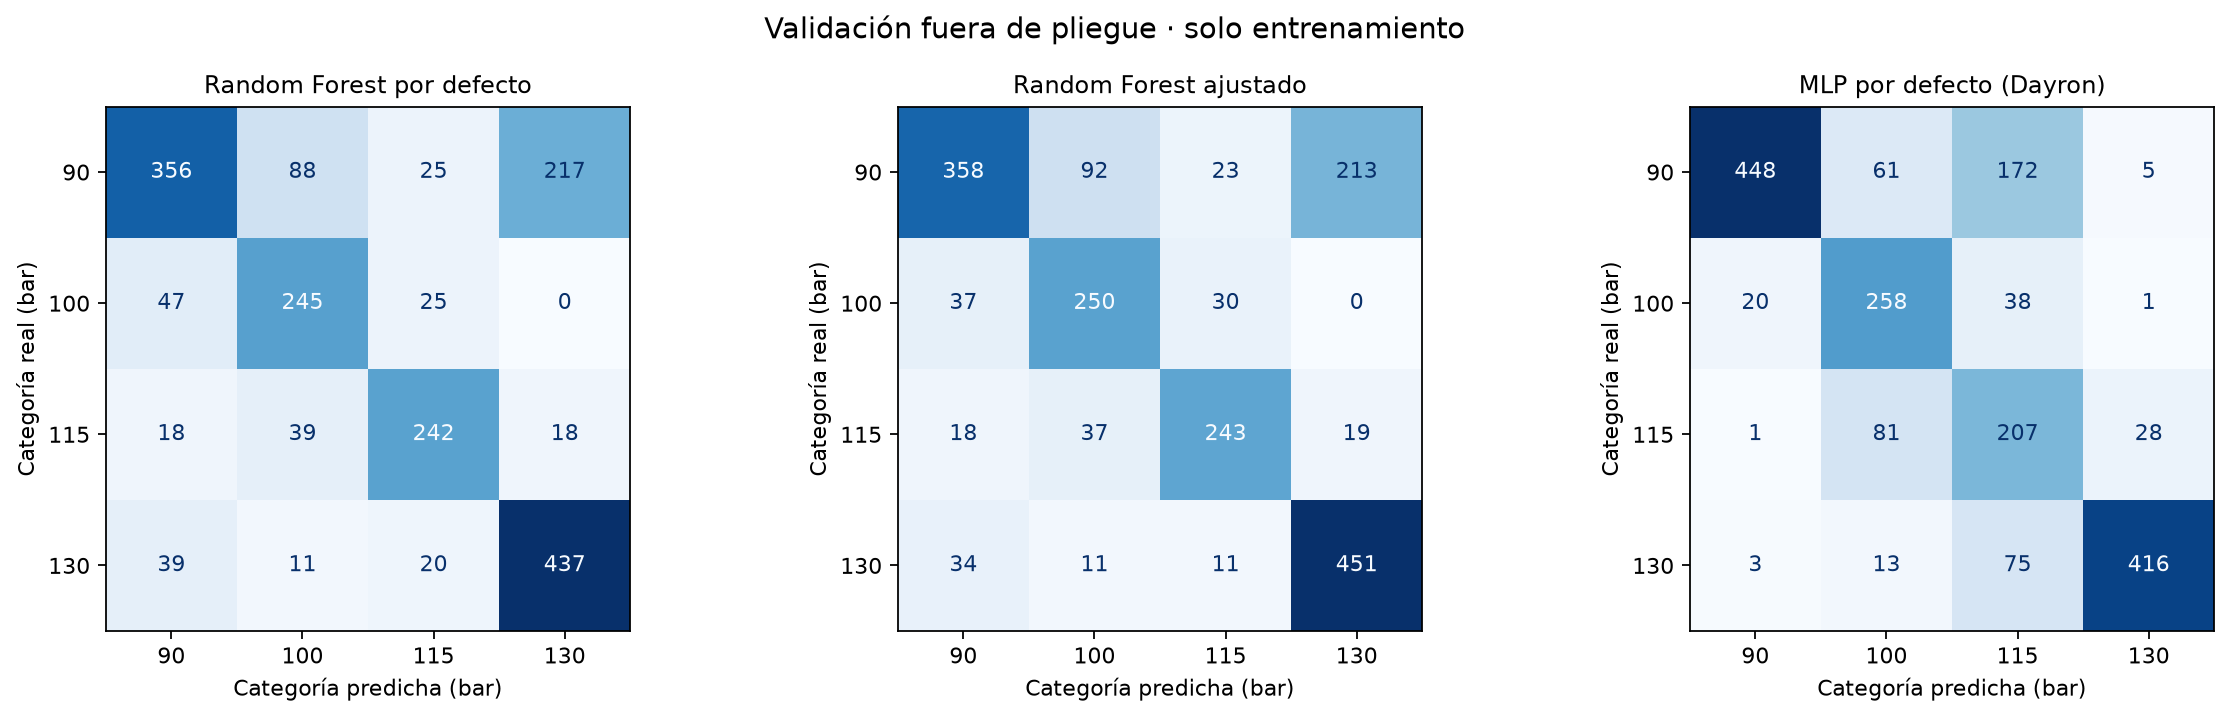

In [5]:
display(tablas["pliegues"].round(4))
display(tablas["metricas_clase"].round(4))
display(Image(filename=str(config.DIR_REPORTES / "figuras" / "matrices_confusion_dayron.png")))

## 5. Trazabilidad y errores que conviene observar
Se guardan las 27 configuraciones de la búsqueda con su puntuación por pliegue, media, desviación y tiempos. También se guardan las predicciones OOF con probabilidades, categoría real, grupo y pliegue.

`indice_entrenamiento` es la posición, desde cero, dentro de la tabla que devuelve `cargar_entrenamiento()`; no es el número de ciclo de los archivos originales. Ninguno de estos identificadores se usa como entrada.

Para mantenimiento conviene distinguir **90 bar predicho como 130** (deterioro clasificado como óptimo) de **130 predicho como 90** (caso óptimo clasificado como deteriorado). Son recuentos de validación de este banco, no estimaciones del tiempo restante hasta una falla.

**Lectura de esta ejecución:** RF ajustado clasifica 213 de los 686 ciclos reales de 90 bar como 130 bar (31,0 %); la MLP base lo hace en 5 (0,7 %). Esto muestra que un F1 macro cercano puede ocultar errores muy distintos. La MLP también se equivoca en las otras categorías: no se concluye que sea el modelo final. Estas confusiones deben discutirse junto con las matrices y las limitaciones de los grupos.

In [6]:
oof = tablas["predicciones_oof"]
assert oof.groupby(["modelo", "indice_entrenamiento"]).size().eq(1).all()
assert oof.groupby("modelo").size().eq(len(X)).all()
assert np.allclose(oof[[f"p_{b}" for b in (90, 100, 115, 130)]].sum(axis=1), 1)
errores_extremos = pd.DataFrame([
    {"modelo": nombre,
     "90 predicho 130": int(((d.real_bar == 90) & (d.pred_bar == 130)).sum()),
     "130 predicho 90": int(((d.real_bar == 130) & (d.pred_bar == 90)).sum())}
    for nombre, d in oof.groupby("modelo", sort=False)
])
display(errores_extremos)

,modelo,90 predicho 130,130 predicho 90
0,Random Forest por defecto,217,39
1,Random Forest ajustado,213,34
2,MLP por defecto (Dayron),5,3


## 6. Comparación con la MLP base de José
José ya evaluó la misma configuración de MLP con semillas 42, 43 y 44 en `03_metaheuristica.ipynb`. Esta ejecución de Dayron sirve como comprobación de la semilla compartida y como aporte a su tarea.

Es la **misma configuración**, no un nuevo método ni una cuarta repetición independiente. En el informe no se deben contar ambas filas como evidencia adicional. Se comparan las métricas, no los tiempos de la ejecución paralela de José.

In [7]:
ruta_jose = config.DIR_REPORTES / "pliegues_jose.csv"
if ruta_jose.exists():
    jose = pd.read_csv(ruta_jose)
    referencia = jose.loc[jose.modelo == f"MLP defecto (semilla {config.RANDOM_STATE})"]
    propia = tablas["pliegues"].loc[tablas["pliegues"].modelo == NOMBRE_MLP]
    if len(referencia) == config.N_PLIEGUES:
        comparacion = propia[["pliegue", "f1_macro"]].merge(
            referencia[["pliegue", "f1_macro"]], on="pliegue",
            suffixes=("_dayron", "_jose"), validate="one_to_one",
        )
        comparacion["diferencia"] = comparacion.f1_macro_dayron - comparacion.f1_macro_jose
        display(comparacion)
        print("Coincidencia de F1 por pliegue:",
              np.allclose(comparacion.f1_macro_dayron, comparacion.f1_macro_jose, atol=1e-10))
    else:
        print("No se encontró la configuración de referencia; no se inventa la comparación.")
else:
    print("La comparación requiere que el aporte de José esté integrado.")

,pliegue,f1_macro_dayron,f1_macro_jose,diferencia
0,0,0.586482,0.586482,0.0
1,1,0.770883,0.770883,0.0
2,2,0.844259,0.844259,0.0
3,3,0.755097,0.755097,0.0
4,4,0.668019,0.668019,0.0


Coincidencia de F1 por pliegue: True


## 7. Lectura de resultados y límites
La búsqueda y la comparación reutilizan los mismos pliegues. Por eso el resultado de RF ajustado tiene sesgo de selección: las OOF son fuera del ajuste de cada pliegue, pero no independientes de la elección de hiperparámetros. No se presentan como resultados finales ni como validación anidada.

Las desviaciones pueden ser grandes porque hay combinaciones con muchos ciclos que dominan algunos pliegues. No se interpreta una diferencia pequeña como superioridad demostrada ni como equivalencia estadística. Las cifras antiguas del contrato eran referencias de dificultad; no se fuerzan los resultados para hacerlas coincidir.

`t_entrenamiento` mide el ajuste medio de cada pliegue. `t_inferencia` mide `predict_proba` sobre su lote de validación. El coste completo de la búsqueda de RF se registra aparte en `entorno_dayron.json`; tampoco se incluye en esos tiempos la segunda pasada OOF.

In [8]:
medias = tablas["pliegues"].groupby("modelo", sort=False).f1_macro.mean()
print("F1 macro medio de validación por grupos:")
for nombre, valor in medias.items():
    print(f"  {nombre}: {valor:.4f}")
print(f"Cambio de RF ajustado respecto al RF base: "
      f"{medias[NOMBRE_RF_AJUSTADO] - medias[NOMBRE_RF_BASE]:+.4f}")
print("La selección final corresponde al equipo y debe considerar todos los modelos.")
entorno = json.loads((config.DIR_REPORTES / "entorno_dayron.json").read_text(encoding="utf-8"))
display(pd.Series({
    k: entorno[k] for k in (
        "sistema", "procesador", "cpu_logicos", "ram_gib", "python",
        "semilla", "n_jobs", "limite_hilos_blas", "segundos_busqueda_rf",
        "segundos_experimento", "avisos_convergencia", "conjunto_prueba_evaluado",
    )
}).to_frame("valor"))
print("Versiones:", entorno["versiones"])

F1 macro medio de validación por grupos:
  Random Forest por defecto: 0.7046
  Random Forest ajustado: 0.7148
  MLP por defecto (Dayron): 0.7249
Cambio de RF ajustado respecto al RF base: +0.0102
La selección final corresponde al equipo y debe considerar todos los modelos.


,valor
sistema,Windows-11-10.0.26200-SP0
procesador,"Intel64 Family 6 Model 154 Stepping 3, Genuine..."
cpu_logicos,12
ram_gib,15.7
python,3.12.14
semilla,42
n_jobs,1
limite_hilos_blas,1
segundos_busqueda_rf,243.925852
segundos_experimento,357.655071


Versiones: {'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'psutil': '7.2.2', 'threadpoolctl': '3.7.0'}


## 8. Reproducir y continuar
Desde la raíz del repositorio, con el entorno y los datos preparados:
```powershell
& ".\.venv\Scripts\python.exe" scripts/entrenar_modelos_dayron.py
```
También se puede ejecutar este notebook completo, sin ejecutar además el script (ambos llaman a la misma implementación).

Archivos generados en `reports/`:
- `resultados_dayron.csv`: tres filas compatibles con la tabla común.
- `pliegues_dayron.csv`: cinco filas por modelo.
- `metricas_clase_dayron.csv` y `matrices_confusion_dayron.csv`: desglose por categoría.
- `predicciones_oof_dayron.csv`: evidencia reproducible de cada predicción de entrenamiento.
- `busqueda_rf_dayron.csv`: rejilla completa evaluada.
- `entorno_dayron.json` y `figuras/matrices_confusion_dayron.png`: condiciones de ejecución y visualización.

La tabla conjunta se comprueba en memoria con `ic_g7.resultados.consolidar()`; se regenera con `scripts/consolidar_resultados.py` cuando el equipo la necesite. Los nombres son distintos de los de José para evitar colisiones.

Pendiente del equipo: selección del modelo, evaluación única en prueba con los tres presentes el 27/oct, exportación del pipeline final, umbral de José e integración en Streamlit.

**Registro de asistencia de IA, 22/oct/2026:** Codex ayudó a estructurar e implementar estos experimentos, documentar el procedimiento y ejecutar las comprobaciones locales. Este apoyo debe incluirse en el anexo final de contribuciones y uso de IA; los integrantes deben comprender y poder explicar el trabajo.